In [229]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm


In [230]:
# Parameters

TICKER = "EXSA.DE"              # ETF Euro Stoxx 50
INITIAL_CAPITAL = 100_000       # 100 000€ initial capital
LOOKBACK = 20                   # 20 days
START_DATE = "2024-11-01"
END_DATE = "2025-12-31"

In [231]:
# Downloading Data from Yahoo Finance

df = yf.download(
    TICKER,
    start=START_DATE,
    end=END_DATE,
    interval="1d",
    auto_adjust=True,
    progress=False
)


In [232]:
# Adjusting columns

if isinstance(df.columns, pd.MultiIndex):
    # if columns are (price, ticker)
    if "Close" in df.columns.get_level_values(0):
        df.columns = df.columns.get_level_values(0)
    # if columns are (ticker, price)
    elif "Close" in df.columns.get_level_values(1):
        df.columns = df.columns.get_level_values(1)


In [233]:
df

Price,Close,High,Low,Open,Volume
Date,,,,,
2024-11-01,47.930042,48.053257,47.531970,47.550922,124657
2024-11-04,47.740482,48.062733,47.740482,47.930042,87131
2024-11-05,47.759441,47.901612,47.626751,47.787874,158051
2024-11-06,47.541447,48.688279,47.437189,48.214381,303130
2024-11-07,47.854225,48.024825,47.607796,47.636229,138993
...,...,...,...,...,...
2025-12-19,56.783543,56.851956,56.490341,56.548983,115539
2025-12-22,56.676037,56.812864,56.539206,56.734675,113363
2025-12-23,56.891052,56.969241,56.754225,56.793320,101383


In [234]:
# We only keep Close and Open
df = df[["Close","Open"]]

C:\Users\antoi\AppData\Local\Temp\ipykernel_17276\3487665326.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


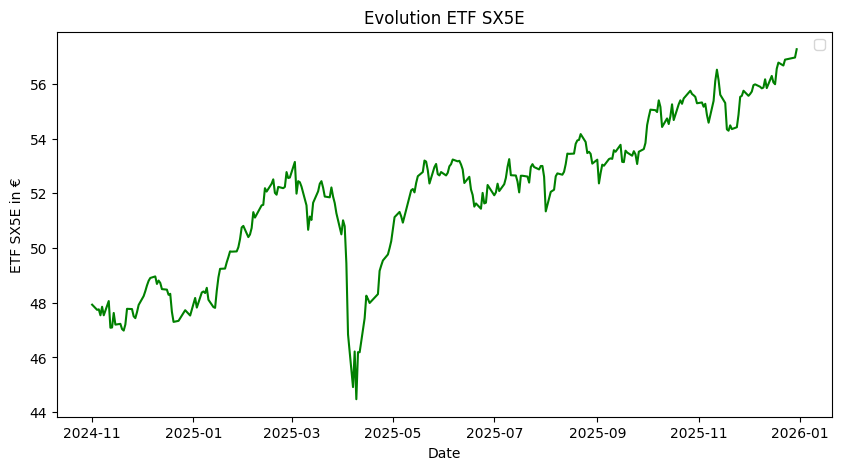

In [235]:
plt.figure(figsize=(10,5))
plt.plot(df.index,df["Close"],color="g")
plt.xlabel("Date")
plt.ylabel("ETF SX5E in €")
plt.legend()
plt.title("Evolution ETF SX5E")
plt.show()


In [236]:
# We calculate the Daily Return 
df["Daily Return"] = df["Close"].pct_change()

C:\Users\antoi\AppData\Local\Temp\ipykernel_17276\1744931298.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Daily Return"] = df["Close"].pct_change()


In [237]:
# we calculate the Daily Volatility
df["Volatility"] = df["Daily Return"].rolling(20).std().shift(1)

# Annualizing the volatility
df["Volatility"] = df["Volatility"]*np.sqrt(252)

C:\Users\antoi\AppData\Local\Temp\ipykernel_17276\2133837815.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Volatility"] = df["Daily Return"].rolling(20).std().shift(1)
C:\Users\antoi\AppData\Local\Temp\ipykernel_17276\2133837815.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Volatility"] = df["Volatility"]*np.sqrt(252)


In [238]:
df

Price,Close,Open,Daily Return,Volatility
Date,,,,
2024-11-01,47.930042,47.550922,NaN,NaN
2024-11-04,47.740482,47.930042,-0.003955,NaN
2024-11-05,47.759441,47.787874,0.000397,NaN
2024-11-06,47.541447,48.214381,-0.004564,NaN
2024-11-07,47.854225,47.636229,0.006579,NaN
...,...,...,...,...
2025-12-19,56.783543,56.548983,0.003974,0.076753
2025-12-22,56.676037,56.734675,-0.001893,0.075279
2025-12-23,56.891052,56.793320,0.003794,0.076622


In [239]:
# We only keep the year 2025 for the backtest
df = df.loc["2025-01-01":"2025-12-31"]


C:\Users\antoi\AppData\Local\Temp\ipykernel_17276\2953287556.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


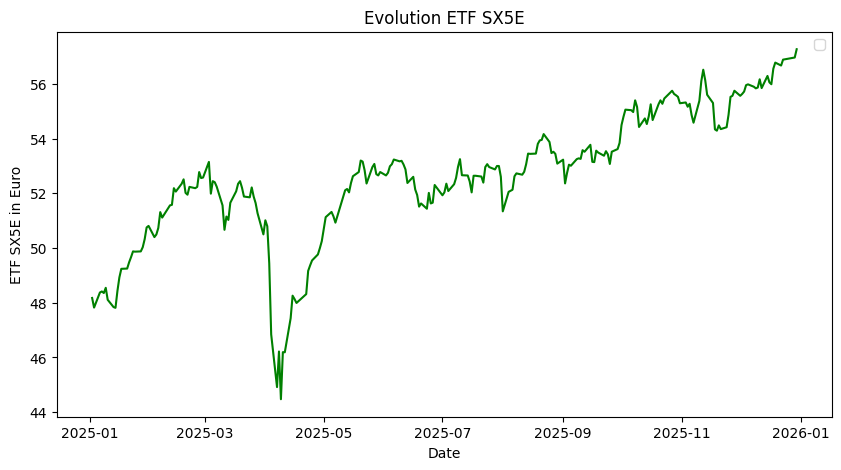

In [240]:
plt.figure(figsize=(10,5))
plt.plot(df.index,df["Close"],color="g")
plt.xlabel("Date")
plt.ylabel("ETF SX5E in Euro")
plt.legend()
plt.title("Evolution ETF SX5E")
plt.show()


In [241]:
df

Price,Close,Open,Daily Return,Volatility
Date,,,,
2025-01-02,48.175289,47.937457,0.013509,0.085953
2025-01-03,47.823303,48.080162,-0.007306,0.097203
2025-01-06,48.375076,47.975520,0.011538,0.099130
2025-01-07,48.413128,48.251404,0.000787,0.104822
2025-01-08,48.356049,48.470207,-0.001179,0.104008
...,...,...,...,...
2025-12-19,56.783543,56.548983,0.003974,0.076753
2025-12-22,56.676037,56.734675,-0.001893,0.075279
2025-12-23,56.891052,56.793320,0.003794,0.076622


In [242]:
# If the underlying asset goes up, we have to hedge by buying the asset
df.loc[df["Daily Return"]>0,"Decision"] = "Long"

# If the underlying asset goes down, we have to hedge by shorting the asset
df.loc[df["Daily Return"]<0,"Decision"] = "Short"

# The decision made today will be the trade executed tomorrow
df["Decision"] = df["Decision"].shift(1).fillna(0)

C:\Users\antoi\AppData\Local\Temp\ipykernel_17276\468413574.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.loc[df["Daily Return"]>0,"Decision"] = "Long"
C:\Users\antoi\AppData\Local\Temp\ipykernel_17276\468413574.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Decision"] = df["Decision"].shift(1).fillna(0)


In [243]:
df

Price,Close,Open,Daily Return,Volatility,Decision
Date,,,,,
2025-01-02,48.175289,47.937457,0.013509,0.085953,0
2025-01-03,47.823303,48.080162,-0.007306,0.097203,Long
2025-01-06,48.375076,47.975520,0.011538,0.099130,Short
2025-01-07,48.413128,48.251404,0.000787,0.104822,Long
2025-01-08,48.356049,48.470207,-0.001179,0.104008,Long
...,...,...,...,...,...
2025-12-19,56.783543,56.548983,0.003974,0.076753,Long
2025-12-22,56.676037,56.734675,-0.001893,0.075279,Long
2025-12-23,56.891052,56.793320,0.003794,0.076622,Short


In [244]:
# Black and Scholes Formula to price a call

# S: value of the underlying asset 
# K: strike
# r: free interest 
# sigma: volatility
# T: maturity

def call_black_scholes(S,K,r,sigma,T):
    d1 = (np.log(S/K)+(((1/2)*(sigma**2))+r)*T)/(sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)

    C = norm.cdf(d1)*S - K*np.exp(-r*T)*norm.cdf(d2)
    C = C.round(2)

    return C

In [245]:
# Delta function: Call's Delta

def delta(S,K,sigma,r,T):
    d1 = (np.log(S/K)+(((1/2)*(sigma**2))+r)*T)/(sigma*np.sqrt(T))
    delta = norm.cdf(d1)
    return delta 

In [246]:
# Delta portfolio

def delta_portfolio(delta_call,delta_value):
    return -delta_call + delta_value

In [247]:
bt = df.copy()
initial_cash = 100_000
nb_call_sold = 100_000


T = (bt.index[-1] - bt.index[0]).days/365   # Maturity until 30/12/2025


S = bt.iloc[0]["Open"]  # 1st value of the Asset at the Open
r = 0.03                # risk free interest rate
K = 55                  # Strike
sigma = bt.iloc[0]["Volatility"] + 150/10000   # we take the initial historical volatility + 150 bps 

# at t=0 

# Call value
premium_call_0 = call_black_scholes(S,K,r,sigma,T)*nb_call_sold

# Delta value
delta_0 = delta(S,K,sigma,r,T)
print(delta_0)

# Hedge in Euro in order to delta hedge the sold call
hedge_in_euro_0 = delta_0 * S * nb_call_sold

# Transaction Fees
fees = 0.005        # Transaction fees rate 50 bps
transaction_cost_0 = hedge_in_euro_0 * fees

# Number of assets held
nb_asset_held = delta_0 * nb_call_sold

# Number of assets bought
nb_asset_bought = nb_asset_held

# Number of assets sold
nb_asset_sold = 0 

# Cash value 
cash = initial_cash + premium_call_0 - (hedge_in_euro_0 + transaction_cost_0)
print(cash)


# Portfolio delta
portfolio_delta = delta_portfolio(delta_call=delta_0,delta_value=delta_0)

# Portfolio value
portfolio_value = -premium_call_0 + hedge_in_euro_0

# daily P&L
daily_pnl = -transaction_cost_0

# cumulative P&L
cumulative_pnl = -transaction_cost_0


# We append all those values into lists
call_value_list = []
call_value_list.append(premium_call_0/nb_call_sold)


cash_list = []
cash_list.append(cash)

delta_list = []
delta_list.append(delta_0)

hedge_in_euro_list = []
hedge_in_euro_list.append(hedge_in_euro_0)

transaction_cost_list = []
transaction_cost_list.append(transaction_cost_0)

nb_asset_held_list = []
nb_asset_held_list.append(nb_asset_held)

nb_asset_bought_list = []
nb_asset_bought_list.append(nb_asset_bought)

nb_asset_sold_list = []
nb_asset_sold_list.append(nb_asset_sold)

portfolio_delta_list = []
portfolio_delta_list.append(portfolio_delta)


# Portfolio 
portfolio_value_list = []
portfolio_value_list.append(portfolio_value) 

# daily P&L
daily_pnl_list = []
daily_pnl_list.append(daily_pnl)

# cumulative P&L
cumulative_pnl_list =[]
cumulative_pnl_list.append(cumulative_pnl)

0.1536734115527661
-603354.6114581279


In [248]:


for date,row in bt.iloc[1:].iterrows(): # we do not take the first row
    
    spot = row["Open"]
    decision = row["Decision"]
    volatility = row["Volatility"]
    
    T = (pd.Timestamp("2025-12-30") - date).days/365   



    if decision == "Short":

        delta_t = delta(spot,K,volatility,r,T)
        premium_call = call_black_scholes(spot,K,r,volatility,T) 
        hedge_in_euro = (delta_list[-1]-delta_t) * spot * nb_call_sold
        nb_asset_sold = (delta_list[-1]-delta_t) * nb_call_sold
        nb_asset_bought = 0
        transaction_cost = hedge_in_euro * fees
        cash = cash + hedge_in_euro - transaction_cost
        portfolio_value = -premium_call*nb_call_sold  + delta_t*spot*nb_call_sold 
        daily_pnl = portfolio_value - portfolio_value_list[-1] - transaction_cost - hedge_in_euro
        cumulative_pnl = portfolio_value - portfolio_value_list[0]
        nb_asset_held = nb_asset_held - nb_asset_sold
        portfolio_delta = -nb_call_sold * delta_t + nb_asset_held
    

    if decision == "Long":

        delta_t = delta(spot,K,volatility,r,T) 
        premium_call = call_black_scholes(spot,K,r,volatility,T)
        hedge_in_euro = (delta_t-delta_list[-1]) * spot * nb_call_sold
        nb_asset_bought = (delta_t-delta_list[-1])* nb_call_sold
        nb_asset_sold = 0 
        transaction_cost = hedge_in_euro * fees
        cash = cash - hedge_in_euro - transaction_cost
        portfolio_value = -premium_call*nb_call_sold  + delta_t*spot*nb_call_sold 
        daily_pnl = portfolio_value - portfolio_value_list[-1] - transaction_cost - hedge_in_euro
        cumulative_pnl = portfolio_value - portfolio_value_list[0]
        nb_asset_held = nb_asset_held + nb_asset_bought
        portfolio_delta = -nb_call_sold * delta_t + nb_asset_held


    
    cash_list.append(cash)
    delta_list.append(delta_t)
    hedge_in_euro_list.append(hedge_in_euro)
    transaction_cost_list.append(transaction_cost)
    call_value_list.append(premium_call)
    PNL_list.append(PNL)
    nb_asset_held_list.append(nb_asset_held)
    nb_asset_bought_list.append(nb_asset_bought)
    nb_asset_sold_list.append(nb_asset_sold)

    portfolio_delta_list.append(portfolio_delta)

    portfolio_value_list.append(portfolio_value)
    daily_pnl_list.append(daily_pnl)
    cumulative_pnl_list.append(cumulative_pnl)



bt["Cash in Euro"] = cash_list
bt["Delta"] = delta_list
bt["Transaction Cost"] = transaction_cost_list
bt["Hedge in Euro"] = hedge_in_euro_list
bt["Call Value"] = call_value_list
bt["Number of assets held"] = nb_asset_held_list
bt["Number of assets bought"] = nb_asset_bought_list
bt["Number of assets sold"] = nb_asset_sold_list
bt["Portfolio Delta"] = portfolio_delta_list
bt["Portfolio value"] = portfolio_value_list
bt["Daily PNL"] = daily_pnl_list
bt["Cumulative PNL"] = cumulative_pnl_list






C:\Users\antoi\AppData\Local\Temp\ipykernel_17276\2940726948.py:4: RuntimeWarning: divide by zero encountered in scalar divide
  d1 = (np.log(S/K)+(((1/2)*(sigma**2))+r)*T)/(sigma*np.sqrt(T))
C:\Users\antoi\AppData\Local\Temp\ipykernel_17276\4074924166.py:10: RuntimeWarning: divide by zero encountered in scalar divide
  d1 = (np.log(S/K)+(((1/2)*(sigma**2))+r)*T)/(sigma*np.sqrt(T))


In [249]:
bt

Price,Close,Open,Daily Return,Volatility,Decision,Cash in Euro,Delta,Transaction Cost,Hedge in Euro,Call Value,Number of assets held,Number of assets bought,Number of assets sold,Portfolio Delta,Portfolio value,Daily PNL,Cumulative PNL
Date,,,,,,,,,,,,,,,,,
2025-01-02,48.175289,47.937457,0.013509,0.085953,0,-6.033546e+05,0.153673,3683.356276,736671.255182,0.37,15367.341155,15367.341155,0.000000,0.000000e+00,6.996713e+05,-3683.356276,-3.683356e+03
2025-01-03,47.823303,48.080162,-0.007306,0.097203,Long,-5.864321e+05,0.150171,-84.191560,-16838.312097,0.35,15017.127861,-350.213295,0.000000,0.000000e+00,6.870259e+05,4277.195636,-1.264531e+04
2025-01-06,48.375076,47.975520,0.011538,0.099130,Short,-5.783021e+05,0.148468,40.854285,8170.857082,0.35,14846.814811,0.000000,170.313049,0.000000e+00,6.772837e+05,-17953.999514,-2.238760e+04
2025-01-07,48.413128,48.251404,0.000787,0.104822,Long,-7.153550e+05,0.176731,681.855089,136371.017886,0.46,17673.074927,2826.260116,0.000000,0.000000e+00,8.067507e+05,-7585.858600,1.070794e+05
2025-01-08,48.356049,48.470207,-0.001179,0.104008,Long,-7.586224e+05,0.185613,215.260888,43052.177570,0.48,18561.294314,888.219387,0.000000,0.000000e+00,8.516698e+05,1651.666361,1.519985e+05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-19,56.783543,56.548983,0.003974,0.076753,Long,-5.262309e+06,0.984574,1435.631753,287126.350676,1.60,98457.433769,5077.480385,0.000000,2.910383e-11,5.407668e+06,-2240.743029,4.707996e+06
2025-12-22,56.676037,56.734675,-0.001893,0.075279,Long,-5.337833e+06,0.997820,375.739989,75147.997892,1.77,99781.985253,1324.551484,0.000000,2.910383e-11,5.484098e+06,907.036676,4.784427e+06
2025-12-23,56.891052,56.793320,0.003794,0.076622,Short,-5.344370e+06,0.998977,-32.846789,-6569.357763,1.83,99897.656565,0.000000,-115.671312,2.910383e-11,5.490520e+06,13023.240869,4.790848e+06


C:\Users\antoi\AppData\Local\Temp\ipykernel_17276\79879977.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


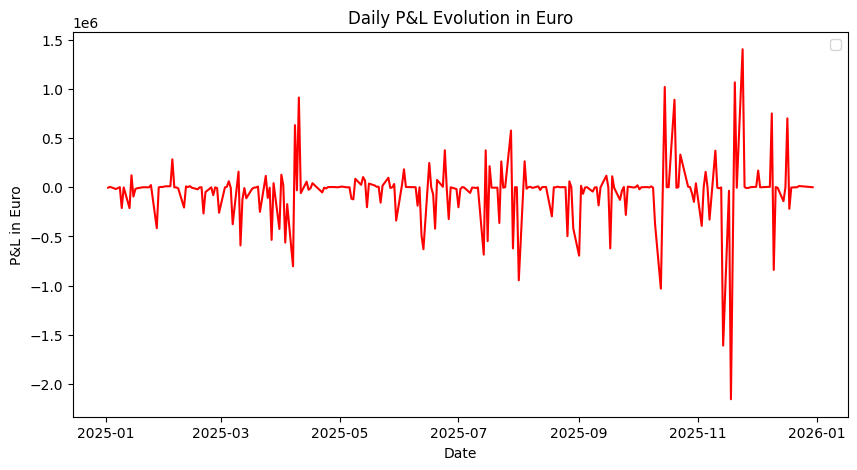

In [250]:
plt.figure(figsize=(10,5))
plt.plot(bt.index,bt["Daily PNL"],color='r')
plt.xlabel("Date")
plt.ylabel("P&L in Euro")
plt.title("Daily P&L Evolution in Euro")
plt.legend()
plt.show()

C:\Users\antoi\AppData\Local\Temp\ipykernel_17276\162974219.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


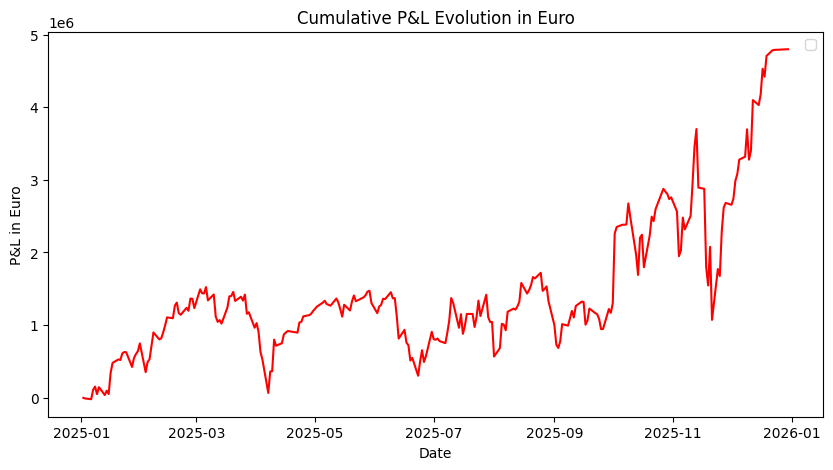

In [251]:
plt.figure(figsize=(10,5))
plt.plot(bt.index,bt["Cumulative PNL"],color='r')
plt.xlabel("Date")
plt.ylabel("P&L in Euro")
plt.title("Cumulative P&L Evolution in Euro")
plt.legend()
plt.show()

C:\Users\antoi\AppData\Local\Temp\ipykernel_17276\3806968646.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


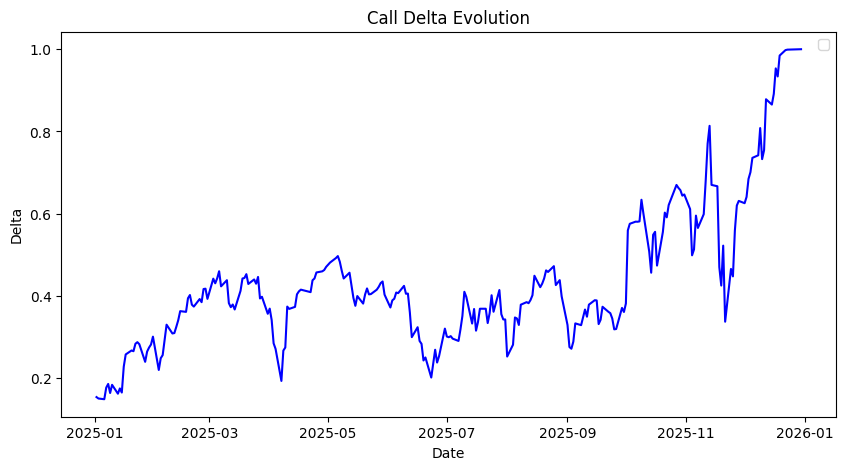

In [252]:
plt.figure(figsize=(10,5))
plt.plot(bt.index,bt["Delta"],color='b')
plt.xlabel("Date")
plt.ylabel("Delta")
plt.title("Call Delta Evolution")
plt.legend()
plt.show()

C:\Users\antoi\AppData\Local\Temp\ipykernel_17276\3538446923.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


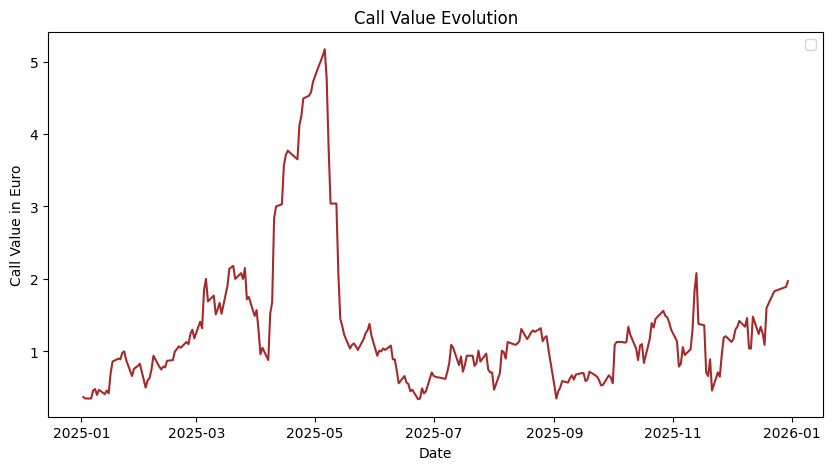

In [253]:
plt.figure(figsize=(10,5))
plt.plot(bt.index,bt["Call Value"],color='brown')
plt.xlabel("Date")
plt.ylabel("Call Value in Euro")
plt.title("Call Value Evolution")
plt.legend()
plt.show()

C:\Users\antoi\AppData\Local\Temp\ipykernel_17276\1826060787.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


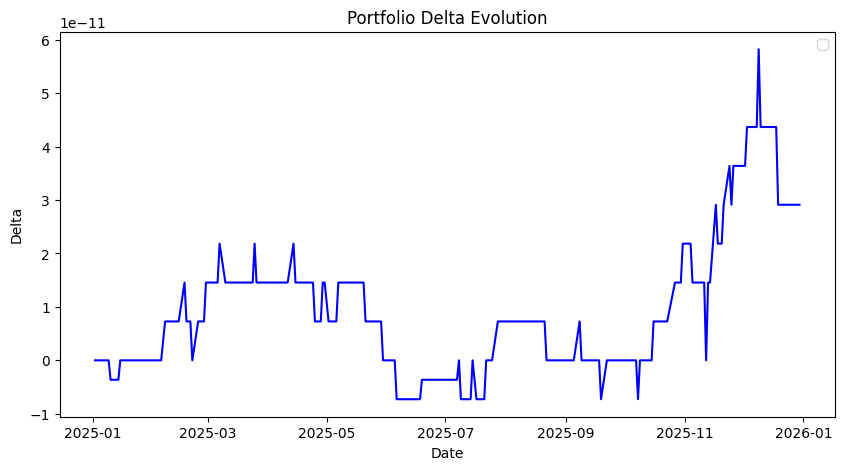

In [254]:
plt.figure(figsize=(10,5))
plt.plot(bt.index,bt["Portfolio Delta"],color='b')
plt.xlabel("Date")
plt.ylabel("Delta")
plt.title("Portfolio Delta Evolution")
plt.legend()
plt.show()

C:\Users\antoi\AppData\Local\Temp\ipykernel_17276\600309972.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


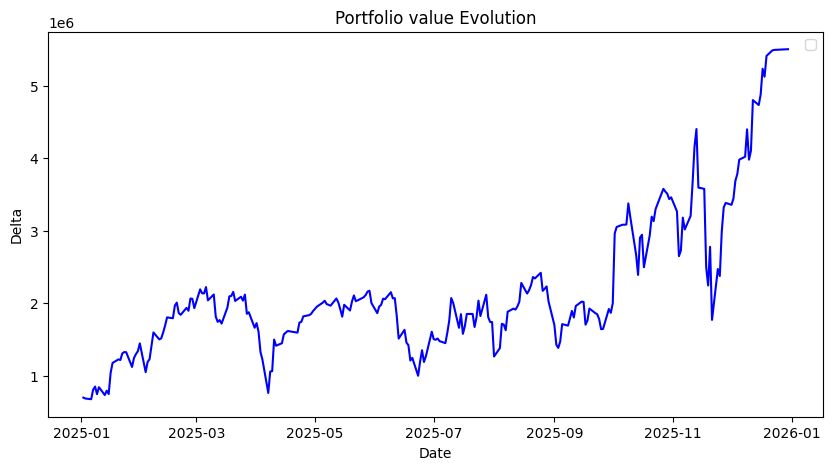

In [228]:
plt.figure(figsize=(10,5))
plt.plot(bt.index,bt["Portfolio value"],color='b')
plt.xlabel("Date")
plt.ylabel("Delta")
plt.title("Portfolio value Evolution")
plt.legend()
plt.show()

C:\Users\antoi\AppData\Local\Temp\ipykernel_17276\1711984235.py:3: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  .resample("M")


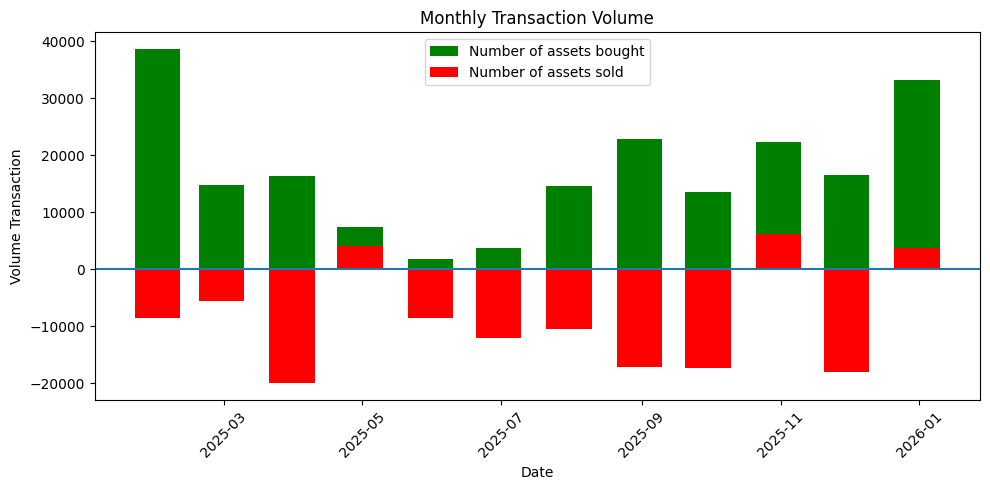

In [255]:
monthly = (
    bt[["Number of assets bought", "Number of assets sold"]]
    .resample("M")
    .sum()
)

plt.figure(figsize=(10,5))
plt.bar(
    monthly.index,
    monthly["Number of assets bought"],
    width = 20,
    label="Number of assets bought",
    color="green"
)

plt.bar(
    monthly.index,
    -monthly["Number of assets sold"],
    width= 20,
    label ="Number of assets sold",
    color="red"
)

plt.axhline(0)
plt.xlabel("Date")
plt.ylabel("Volume Transaction")
plt.title("Monthly Transaction Volume")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [256]:
# Sum of Transaction Fees during the backtest
bt["Transaction Cost"].sum()

np.float64(81908.84594528814)

In [145]:
summary = pd.DataFrame({
"02/01/2025":{
    "P&L in €":0,
    "Number of assets held":bt.iloc[0]["Number of assets held"],
    "Asset Price in €":bt.iloc[0]["Close"],
    "Call Delta":bt.iloc[0]["Delta"],
    "Call Value in €":bt.iloc[0]["Call Value"]
    },

"30/12/2025":{
    "P&L in €":bt.iloc[-1]["Cumulative PNL"],
    "Number of assets held":bt.iloc[-1]["Number of assets held"],
    "Asset Price in €":bt.iloc[-1]["Close"],
    "Call Delta":bt.iloc[-1]["Delta"],
    "Call Value in €":bt.iloc[-1]["Call Value"]
    },

})

In [ ]:
summary

,02/01/2025,30/12/2025
P&L in €,0.000000,2.107224e+06
Number of assets held,15367.341155,1.000000e+05
Asset Price in €,48.175289,5.727222e+01
Call Delta,0.153673,1.000000e+00
Call Value in €,0.370000,1.970000e+00


Delta hedging a call option written on the SX5E ETF, with Strike K = 55, Maturity T = 0.9 years allows us to generate a positive P&L at maturity.

Overall, the delta hedge is well implemented, even though our portfolio is not delta-neutral on a daily basis. In some instances, however, we observe a negative P&L during the study period, mainly due to highly volatile market movements. In particular, between April and May 2025, our hedging strategy led us to short a substantial amount of the underlying asset while the call option was deeply in the money.

Our analysis is limited to delta hedging only, which is not fully accurate. Indeed, on the one hand, we use a risk-free interest rate that is constant throughout the study; on the other hand, we rely on realized volatility both to price the call option and to compute the delta. However, the Black–Scholes framework assumes the use of implied volatility, which is not calculated within the scope of this study.

Finally, we buy and sell large quantities of the underlying asset in order to hedge our position, which inevitably has an impact on the underlying price itself. Since this analysis is based on a backtest, we are inherently limited in this respect.